# Manufactured solution for the h-mortars test (NavierStokes/hMortars_MMS)

Density and velocity of the manufactured solution of `test/NavierStokes/LambVector`, with `x+y+z` replaced by `k_x x + k_y y + k_z z`, $k_i = 2\pi/L_i$, so that it is periodic in a box of size $L_x \times L_y \times L_z$. The h-mortars test uses $L_x = L_y = 6$ and $k_z = 0$.

The viscous flux follows `ViscousFlux_STATE` (Physics_NS.f90): $F = F_{inviscid} - F_{viscous}$ with the dimensionless `mu` $= 1/Re$ and `kappa` $= 1/((\gamma-1) M^2 Re Pr)$ (`dimensionless % mu`, `dimensionless % kappa`).

The solver computes the viscosity with Sutherland's law, $\mu = \mu_0 f(T)$ with $f(1) = 1$. The energy is chosen so that $p = \rho/(\gamma M^2)$, i.e. the dimensionless temperature $T = \gamma M^2 p/\rho = 1$ everywhere. Then the viscosity is exactly the constant $\mu_0 = 1/Re$ assumed below, and the heat flux vanishes.

In [1]:
import numpy as np
from sympy import *
init_printing()

In [2]:
# Define symbols
x, y, z, t = symbols('x y z t', real=True)

In [3]:
# Define gradient and divergence operators
def gradient(f):
    if isinstance(f, NDimArray):
        return Matrix([[diff(f[0], x), diff(f[0], y), diff(f[0], z)],
                    [diff(f[1], x), diff(f[1], y), diff(f[1], z)],
                    [diff(f[2], x), diff(f[2], y), diff(f[2], z)]])
    else:
        return Array([diff(f, x), diff(f, y), diff(f, z)])
# gradient = lambda f: Array([diff(f, x), diff(f, y), diff(f, z)])
# gradientVector = lambda f: Matrix([[diff(f[0], x), diff(f[0], y), diff(f[0], z)],
#                                    [diff(f[1], x), diff(f[1], y), diff(f[1], z)],
#                                    [diff(f[2], x), diff(f[2], y), diff(f[2], z)]])
def divergence(f):
    if isinstance(f, NDimArray):
        return diff(f[0], x) + diff(f[1], y) + diff(f[2], z)
    elif isinstance(f, MatrixBase):
        return Array([diff(f[0,0], x) + diff(f[1,0], y) + diff(f[2,0], z),
                    diff(f[0,1], x) + diff(f[1,1], y) + diff(f[2,1], z),
                    diff(f[0,2], x) + diff(f[1,2], y) + diff(f[2,2], z)])
    else:
        print("Type: ", type(f))
        raise ValueError("Unknown type in divergence")
# divergenceTensor = lambda f: Array([diff(f[0,0], x) + diff(f[1,0], y) + diff(f[2,0], z),
#                                     diff(f[0,1], x) + diff(f[1,1], y) + diff(f[2,1], z),
#                                     diff(f[0,2], x) + diff(f[1,2], y) + diff(f[2,2], z)])

In [4]:
# Define symbols
mu, Lambda = symbols('mu lambda', real=True)
gamma, Pr, Mach = symbols('gamma Pr M', real=True)
kappa = symbols('kappa', real=True)
kx, ky, kz = symbols('k_x k_y k_z', real=True, positive=True)


In [5]:
# Density
rho_func = Function('rho')
rho = rho_func(x,y,z,t)
# Velocity
u_func = Function('u')
v_func = Function('v')
w_func = Function('w')
u = u_func(x,y,z,t)
v = v_func(x,y,z,t)
w = w_func(x,y,z,t)
vel = Array([u, v, w])
# Pressure
# p_func = Function('p')
# p = p_func(x,y,z,t)
# Energy
E_func = Function('E')
E = E_func(x,y,z,t)
# Temperature
T_func= Function('T')
T = T_func(x,y,z,t)
# Manufactured solution source term
srho_func = Function('s_rho')
srho = srho_func(x,y,z,t)
srhou_func = Function('s_rhou')
srhov_func = Function('s_rhov')
srhow_func = Function('s_rhow')
srhoE_func = Function('s_rhoe')
srhou = srhou_func(x,y,z,t)
srhov = srhov_func(x,y,z,t)
srhow = srhow_func(x,y,z,t)
srhoE = srhoE_func(x,y,z,t)
s_vel = Array([srhou, srhov, srhow])

## Navier-Stokes equations

In [6]:
gradVel = gradient(vel)
gradVel

⎡∂                  ∂                  ∂                ⎤
⎢──(u(x, y, z, t))  ──(u(x, y, z, t))  ──(u(x, y, z, t))⎥
⎢∂x                 ∂y                 ∂z               ⎥
⎢                                                       ⎥
⎢∂                  ∂                  ∂                ⎥
⎢──(v(x, y, z, t))  ──(v(x, y, z, t))  ──(v(x, y, z, t))⎥
⎢∂x                 ∂y                 ∂z               ⎥
⎢                                                       ⎥
⎢∂                  ∂                  ∂                ⎥
⎢──(w(x, y, z, t))  ──(w(x, y, z, t))  ──(w(x, y, z, t))⎥
⎣∂x                 ∂y                 ∂z               ⎦

In [7]:
divVel = divergence(vel)
divVel

In [8]:
gradu = gradVel[0,:]
gradv = gradVel[1,:]
gradw = gradVel[2,:]

In [9]:
gradT = Array([(gamma-1)*gamma*Mach**2*( S(1)/rho*diff(rho*E,x) - (rho*E)/rho**2*diff(rho,x)-u*gradu[0]-v*gradv[0]-w*gradw[0]),
               (gamma-1)*gamma*Mach**2*( S(1)/rho*diff(rho*E,y) - (rho*E)/rho**2*diff(rho,y)-u*gradu[1]-v*gradv[1]-w*gradw[1]),
               (gamma-1)*gamma*Mach**2*( S(1)/rho*diff(rho*E,z) - (rho*E)/rho**2*diff(rho,z)-u*gradu[2]-v*gradv[2]-w*gradw[2])])
gradT

⎡             ⎛              ∂                                 ∂               ↪
⎢             ⎜E(x, y, z, t)⋅──(ρ(x, y, z, t)) + ρ(x, y, z, t)⋅──(E(x, y, z, t ↪
⎢ 2           ⎜              ∂x                                ∂x              ↪
⎢M ⋅γ⋅(γ - 1)⋅⎜─────────────────────────────────────────────────────────────── ↪
⎣             ⎝                          ρ(x, y, z, t)                         ↪

↪                    ∂                                                         ↪
↪ ))   E(x, y, z, t)⋅──(ρ(x, y, z, t))                                         ↪
↪                    ∂x                                ∂                       ↪
↪ ── - ─────────────────────────────── - u(x, y, z, t)⋅──(u(x, y, z, t)) - v(x ↪
↪               ρ(x, y, z, t)                          ∂x                      ↪

↪                                                               ⎞              ↪
↪                                                               ⎟              ↪
↪            ∂            

In [10]:
# Viscous flux
Fviscous_q_d = MutableDenseNDimArray([[S(0), S(0), S(0)],
                      [mu * (2 * gradu[0] - S(2)/3 * divVel), S(0), S(0)],
                      [mu * (gradv[0] + gradu[1]), mu * (2 * gradv[1] - S(2)/3 * divVel), S(0)],
                      [mu * (gradw[0] + gradu[2]), mu * (gradw[1] + gradv[2]), mu * (2 * gradw[2] - S(2)/3 * divVel)],
                      [S(0), S(0), S(0)]])
Fviscous_q_d[1,1] = Fviscous_q_d[2,0]
Fviscous_q_d[1,2] = Fviscous_q_d[3,0]
Fviscous_q_d[2,2] = Fviscous_q_d[3,1]
Fviscous_q_d[4,0] = Fviscous_q_d[1,0]*u + Fviscous_q_d[2,0]*v + Fviscous_q_d[3,0]*w + kappa * gradT[0]
Fviscous_q_d[4,1] = Fviscous_q_d[1,1]*u + Fviscous_q_d[2,1]*v + Fviscous_q_d[3,1]*w + kappa * gradT[1]
Fviscous_q_d[4,2] = Fviscous_q_d[1,2]*u + Fviscous_q_d[2,2]*v + Fviscous_q_d[3,2]*w + kappa * gradT[2]
Fviscous_q_d

⎡                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                           

In [11]:
# Pressure
p = (gamma - 1) * (rho*E - S(1)/2 * (rho*u**2 + rho*v**2 + rho*w**2))

In [12]:
# Inviscid/Euler flux
Finviscid_q_d = MutableDenseNDimArray([[rho*u, rho*v, rho*w],
                                       [rho*u**2+p, S(0), S(0)],
                                       [rho*u*v, rho*v**2+p, S(0)],
                                       [rho*u*w, rho*v*w, rho*w**2+p],
                                       [(rho*E+p)*u, (rho*E+p)*v, (rho*E+p)*w]])
Finviscid_q_d[1,1] = Finviscid_q_d[2,0]
Finviscid_q_d[1,2] = Finviscid_q_d[3,0]
Finviscid_q_d[2,2] = Finviscid_q_d[3,1]
Finviscid_q_d

⎡                                                                          ρ(x ↪
⎢                                                                              ↪
⎢               ⎛                                             2                ↪
⎢               ⎜                              ρ(x, y, z, t)⋅u (x, y, z, t)    ↪
⎢       (γ - 1)⋅⎜E(x, y, z, t)⋅ρ(x, y, z, t) - ──────────────────────────── -  ↪
⎢               ⎝                                           2                  ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                   ρ(x, y, z, ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                           

### Rho equation

In [13]:
rhodt = diff(rho, t)
Frho = Finviscid_q_d[0,:] - Fviscous_q_d[0,:]
# divergence(Frho)
Eqrho = Eq(rhodt + divergence(Frho), srho)
Eqrho

### Rho*u equations

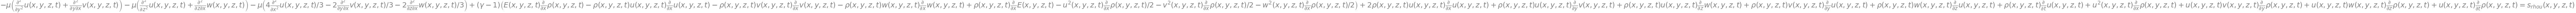

In [14]:
rhoudt = diff(rho*u,t)
Frhou =  Finviscid_q_d[1,:] - Fviscous_q_d[1,:]
Eqrhou = Eq(rhoudt + divergence(Frhou), srhou)
Eqrhou

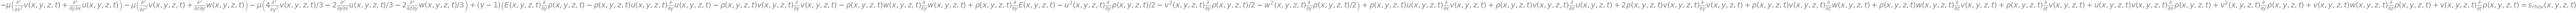

In [15]:
rhovdt = diff(rho*v,t)
Frhov =  Finviscid_q_d[2,:] - Fviscous_q_d[2,:]
Eqrhov = Eq(rhovdt + divergence(Frhov), srhov)
Eqrhov

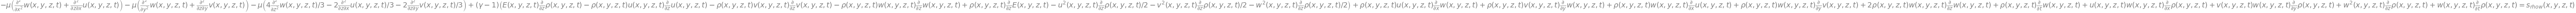

In [16]:
rhowdt = diff(rho*w,t)
Frhow =  Finviscid_q_d[3,:] - Fviscous_q_d[3,:]
Eqrhow = Eq(rhowdt + divergence(Frhow), srhow)
Eqrhow

### Rho*e equation



In [17]:
rhoEdt = diff(rho*E,t)
FrhoE = Finviscid_q_d[4,:] - Fviscous_q_d[4,:]
EqrhoE = Eq(rhoEdt + divergence(FrhoE), srhoE)
EqrhoE

# Manufactured solution

## Write the prescribed solution

In [18]:
# Define manufactured solutions for each variable
s = kx*x + ky*y + kz*z
rho_ms = S(3) + sin(s)*exp(t)
u_ms = cos(s)*exp(-t)
v_ms = sin(s)*exp(-t)
w_ms = cos(s)*exp(-t)
# p = rho/(gamma M^2): uniform temperature T = 1, so Sutherland's law gives mu = 1/Re
E_ms = S(1)/(gamma*(gamma-1)*Mach**2) + (u_ms**2+v_ms**2+w_ms**2) / S(2)


In [19]:
# Replace 
Eqrho_2 = Eqrho.subs([(rho,rho_ms), (u,u_ms), (v,v_ms), (w,w_ms), (E,E_ms)])
Eqrhou_2 = Eqrhou.subs([(rho,rho_ms), (u,u_ms), (v,v_ms), (w,w_ms), (E,E_ms)])
Eqrhov_2 = Eqrhov.subs([(rho,rho_ms), (u,u_ms), (v,v_ms), (w,w_ms), (E,E_ms)])
Eqrhow_2 = Eqrhow.subs([(rho,rho_ms), (u,u_ms), (v,v_ms), (w,w_ms), (E,E_ms)])
EqrhoE_2 = EqrhoE.subs([(rho,rho_ms), (u,u_ms), (v,v_ms), (w,w_ms), (E,E_ms)])

## Solve for the source term

### Solve $s_{\rho}$

In [20]:
# The equation reads lhs = source, so the source is the lhs evaluated (solve() is very slow here)
res_srho = Eqrho_2.lhs.doit()
res_srho

In [21]:
print(res_srho)

-k_x*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-t)*sin(k_x*x + k_y*y + k_z*z) + k_x*cos(k_x*x + k_y*y + k_z*z)**2 + k_y*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-t)*cos(k_x*x + k_y*y + k_z*z) + k_y*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z) - k_z*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-t)*sin(k_x*x + k_y*y + k_z*z) + k_z*cos(k_x*x + k_y*y + k_z*z)**2 + exp(t)*sin(k_x*x + k_y*y + k_z*z)


### Solve $s_{\rho \mathbf{u}}$

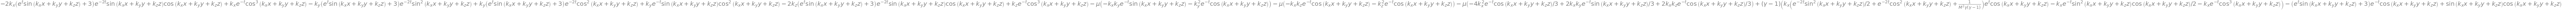

In [22]:
# The equation reads lhs = source, so the source is the lhs evaluated (solve() is very slow here)
res_srhou = Eqrhou_2.lhs.doit()
res_srhou

In [23]:
print(res_srhou)

-2*k_x*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z) + k_x*exp(-t)*cos(k_x*x + k_y*y + k_z*z)**3 - k_y*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2 + k_y*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + k_y*exp(-t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z)**2 - 2*k_z*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z) + k_z*exp(-t)*cos(k_x*x + k_y*y + k_z*z)**3 - mu*(-k_x*k_y*exp(-t)*sin(k_x*x + k_y*y + k_z*z) - k_y**2*exp(-t)*cos(k_x*x + k_y*y + k_z*z)) - mu*(-k_x*k_z*exp(-t)*cos(k_x*x + k_y*y + k_z*z) - k_z**2*exp(-t)*cos(k_x*x + k_y*y + k_z*z)) - mu*(-4*k_x**2*exp(-t)*cos(k_x*x + k_y*y + k_z*z)/3 + 2*k_x*k_y*exp(-t)*sin(k_x*x + k_y*y + k_z*z)/3 + 2*k_x*k_z*exp(-t)*cos(k_x*x + k_y*y + k_z*z)/3) + (gamma - 1)*(k_x*(exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2/2 + exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 

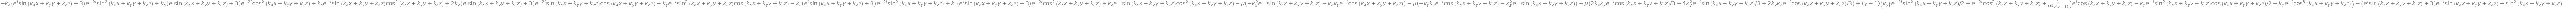

In [24]:
# The equation reads lhs = source, so the source is the lhs evaluated (solve() is very slow here)
res_srhov = Eqrhov_2.lhs.doit()
res_srhov

In [25]:
print(res_srhov)

-k_x*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2 + k_x*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + k_x*exp(-t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z)**2 + 2*k_y*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z) + k_y*exp(-t)*sin(k_x*x + k_y*y + k_z*z)**2*cos(k_x*x + k_y*y + k_z*z) - k_z*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2 + k_z*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + k_z*exp(-t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z)**2 - mu*(-k_x**2*exp(-t)*sin(k_x*x + k_y*y + k_z*z) - k_x*k_y*exp(-t)*cos(k_x*x + k_y*y + k_z*z)) - mu*(-k_y*k_z*exp(-t)*cos(k_x*x + k_y*y + k_z*z) - k_z**2*exp(-t)*sin(k_x*x + k_y*y + k_z*z)) - mu*(2*k_x*k_y*exp(-t)*cos(k_x*x + k_y*y + k_z*z)/3 - 4*k_y**2*exp(-t)*sin(k_x*x + k_y*y + k_z*z)/3 + 2*k_y*k_z*exp(-t)*cos(k_x*x + k_y*y + k

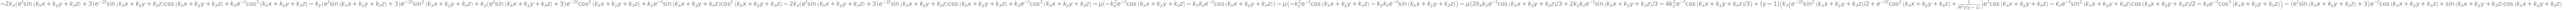

In [26]:
# The equation reads lhs = source, so the source is the lhs evaluated (solve() is very slow here)
res_srhow = Eqrhow_2.lhs.doit()
res_srhow

In [27]:
print(res_srhow)

-2*k_x*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z) + k_x*exp(-t)*cos(k_x*x + k_y*y + k_z*z)**3 - k_y*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2 + k_y*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + k_y*exp(-t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z)**2 - 2*k_z*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z) + k_z*exp(-t)*cos(k_x*x + k_y*y + k_z*z)**3 - mu*(-k_x**2*exp(-t)*cos(k_x*x + k_y*y + k_z*z) - k_x*k_z*exp(-t)*cos(k_x*x + k_y*y + k_z*z)) - mu*(-k_y**2*exp(-t)*cos(k_x*x + k_y*y + k_z*z) - k_y*k_z*exp(-t)*sin(k_x*x + k_y*y + k_z*z)) - mu*(2*k_x*k_z*exp(-t)*cos(k_x*x + k_y*y + k_z*z)/3 + 2*k_y*k_z*exp(-t)*sin(k_x*x + k_y*y + k_z*z)/3 - 4*k_z**2*exp(-t)*cos(k_x*x + k_y*y + k_z*z)/3) + (gamma - 1)*(k_z*(exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2/2 + exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 +

### Solve $s_{\rho E}$



In [28]:
# The equation reads lhs = source, so the source is the lhs evaluated (solve() is very slow here)
res_srhoE = EqrhoE_2.lhs.doit()
res_srhoE

In [29]:
print(res_srhoE)

-M**2*gamma*kappa*(gamma - 1)*(-k_x**2*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2 + k_x**2*exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + k_x**2*(exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2/2 + exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + 1/(M**2*gamma*(gamma - 1)))*exp(t)*sin(k_x*x + k_y*y + k_z*z)/(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3) + k_x**2*exp(-t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z)**2/(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3) + k_x**2*(exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2/2 + exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + 1/(M**2*gamma*(gamma - 1)))*exp(2*t)*cos(k_x*x + k_y*y + k_z*z)**2/(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)**2 - k_x*(-k_x*(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)*exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)*cos(k_x*x + k_y*y + k_z*z) + k_x*(exp(-2*t)*sin(k_x*x + k_y*y + k_z*z)**2/2 + exp(-2*t)*cos(k_x*x + k_y*y + k_z*z)**2 + 1/(M**2*gamma*(gamma - 1)))*exp(t)*cos(k_x*x + k_y*y + k_z*z))*exp(t)*cos(k_x*x + k_y*y + k_z*z)/(exp(t)*sin(k_x*x + k_y*y + k_z*z) + 3)**2 + (k_

## Fortran code for `UserDefinedSourceTermNS`

Written in terms of `sn = sin(s)`, `cs = cos(s)`, `et = exp(t)`.

In [30]:
import re as rx
sn, cs, et = symbols('sn cs et', real=True)
ren = {kx: Symbol('kx'), ky: Symbol('ky'), kz: Symbol('kz')}

def compact(e):
    e = e.subs({sin(s): sn, cos(s): cs}).subs(exp(t), et)
    e = e.subs({exp(-t): 1/et, exp(-2*t): 1/et**2, exp(-3*t): 1/et**3})
    return collect(expand(e), [mu, kappa, Mach], func=factor).subs(ren)

def wrap(lhs, rhs, width=100):
    lines, cur = [], f'{lhs} ='
    for w_ in rhs.split(' '):
        if len(cur) + 1 + len(w_) > width:
            lines.append(cur + ' &'); cur = '   '
        cur += ' ' + w_
    lines.append(cur)
    return '\n'.join('            ' + l for l in lines)

def to_fortran(lhs, e):
    f = str(compact(e)).replace('**', '^')
    f = rx.sub(r'(?<![\w.^])(\d+)(?![\w.])', r'\1.0_RP', f)   # real literals, exponents stay integer
    return wrap(lhs, f.replace('^', '**'))

for lhs, e in [('S(IRHO)', res_srho), ('S(IRHOU)', res_srhou), ('S(IRHOV)', res_srhov),
               ('S(IRHOW)', res_srhow), ('S(IRHOE)', res_srhoE)]:
    print(to_fortran(lhs, e))


            S(IRHO) = (cs**2*et*kx + cs**2*et*kz + 2.0_RP*cs*et*ky*sn + 3.0_RP*cs*ky + et**2*sn - et*kx*sn**2 - &
                et*kz*sn**2 - 3.0_RP*kx*sn - 3.0_RP*kz*sn)/et
            S(IRHOU) = mu*(4.0_RP*cs*kx**2 + cs*kx*kz + 3.0_RP*cs*ky**2 + 3.0_RP*cs*kz**2 + &
                kx*ky*sn)/(3.0_RP*et) + (cs**3*et*kx + cs**3*et*kz + 2.0_RP*cs**2*et*ky*sn + 3.0_RP*cs**2*ky - &
                2.0_RP*cs*et*kx*sn**2 - 2.0_RP*cs*et*kz*sn**2 - 3.0_RP*cs*et - 6.0_RP*cs*kx*sn - 6.0_RP*cs*kz*sn &
                - et*ky*sn**3 - 3.0_RP*ky*sn**2)/et**2 + cs*et*kx/(M**2*gamma)
            S(IRHOV) = mu*(cs*kx*ky + cs*ky*kz + 3.0_RP*kx**2*sn + 4.0_RP*ky**2*sn + &
                3.0_RP*kz**2*sn)/(3.0_RP*et) + (2.0_RP*cs**2*et*kx*sn + 2.0_RP*cs**2*et*kz*sn + 3.0_RP*cs**2*kx &
                + 3.0_RP*cs**2*kz + 3.0_RP*cs*et*ky*sn**2 + 6.0_RP*cs*ky*sn - et*kx*sn**3 - et*kz*sn**3 - &
                3.0_RP*et*sn - 3.0_RP*kx*sn**2 - 3.0_RP*kz*sn**2)/et**2 + cs*et*ky/(M**2*gamma)
            S(IRHO

            S(IRHOE) = 2.0_RP*mu*(2.0_RP*cs**2*kx**2 + cs**2*kx*kz + cs**2*ky**2 + 2.0_RP*cs**2*kz**2 + &
                2.0_RP*cs*kx*ky*sn + 2.0_RP*cs*ky*kz*sn - 2.0_RP*kx**2*sn**2 - kx*kz*sn**2 - ky**2*sn**2 - &
                2.0_RP*kz**2*sn**2)/(3.0_RP*et**2) + (2.0_RP*cs**4*et*kx + 2.0_RP*cs**4*et*kz + &
                4.0_RP*cs**3*et*ky*sn + 6.0_RP*cs**3*ky - 2.0_RP*cs**2*et**2*sn - 3.0_RP*cs**2*et*kx*sn**2 - &
                3.0_RP*cs**2*et*kz*sn**2 - 12.0_RP*cs**2*et - 12.0_RP*cs**2*kx*sn - 12.0_RP*cs**2*kz*sn - &
                3.0_RP*cs*ky*sn**2 - et**2*sn**3 - et*kx*sn**4 - et*kz*sn**4 - 6.0_RP*et*sn**2 - 3.0_RP*kx*sn**3 &
                - 3.0_RP*kz*sn**3)/(2.0_RP*et**3) + (cs**2*et*gamma*kx + cs**2*et*gamma*kz + &
                2.0_RP*cs*et*gamma*ky*sn + 3.0_RP*cs*gamma*ky + et**2*sn - et*gamma*kx*sn**2 - et*gamma*kz*sn**2 &
                - 3.0_RP*gamma*kx*sn - 3.0_RP*gamma*kz*sn)/(M**2*et*gamma*(gamma - 1.0_RP))
